<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Vector_autoregressive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# VAR-BASED MULTIVARIATE FORECASTING TRADING STRATEGY
# NIFTY 50 | ALGORITHMIC TRADING
# ============================================================

# ============================================================
# 1. INSTALL LIBRARIES
# ============================================================

!pip -q install yfinance backtesting quantstats statsmodels

# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import quantstats as qs

from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller

from backtesting import Backtest, Strategy
from backtesting.lib import crossover

# Disable Bokeh notebook warning
from backtesting import set_bokeh_output
set_bokeh_output(notebook=False)

# ============================================================
# 3. DOWNLOAD NIFTY 50 DATA
# ============================================================

ticker = "^NSEI"

data = yf.download(
    ticker,
    start="2018-01-01",
    end="2026-01-01",
    auto_adjust=False,
    progress=False
)

# Handle MultiIndex columns from yfinance
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data[["Open", "High", "Low", "Close", "Volume"]].dropna()

print("=" * 70)
print("NIFTY 50 DATA")
print("=" * 70)

print("Data shape:", data.shape)
print(data.head())


# ============================================================
# 4. CREATE MULTIVARIATE VARIABLES
# ============================================================

df = data.copy()

# Daily return
df["Return"] = df["Close"].pct_change()

# Realized volatility
df["Volatility"] = (
    df["Return"]
    .rolling(10)
    .std()
)

# Volume percentage change
df["Volume_Change"] = (
    df["Volume"]
    .pct_change()
)

# High-Low range
df["Range"] = (
    (df["High"] - df["Low"]) / df["Close"]
)

# Keep variables required by VAR
var_df = df[
    [
        "Return",
        "Volatility",
        "Volume_Change",
        "Range"
    ]
].dropna()

# Remove extreme infinite observations
var_df = var_df.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

print("\nVAR dataset shape:", var_df.shape)
print(var_df.head())


# ============================================================
# 5. STATIONARITY TEST
# ============================================================

print("\n" + "=" * 70)
print("ADF STATIONARITY TEST")
print("=" * 70)

for column in var_df.columns:

    result = adfuller(
        var_df[column],
        autolag="AIC"
    )

    print(
        f"{column:20s} "
        f"ADF Statistic = {result[0]:.4f} | "
        f"p-value = {result[1]:.4f}"
    )


# ============================================================
# 6. VAR FORECAST FUNCTION
# ============================================================

def generate_var_forecast(
    training_data,
    test_data,
    lag=5
):

    train = training_data.copy()

    test = test_data.copy()

    forecasts = []

    for i in range(len(test)):

        # Data available up to current test point
        current_train = pd.concat(
            [
                train,
                test.iloc[:i]
            ]
        )

        try:

            model = VAR(
                current_train
            )

            fitted_model = model.fit(
                lag
            )

            # Last lag observations
            lagged_values = (
                current_train
                .values[-lag:]
            )

            forecast = fitted_model.forecast(
                lagged_values,
                steps=1
            )

            predicted_return = forecast[0][0]

        except Exception:

            predicted_return = 0.0

        forecasts.append(
            predicted_return
        )

    return np.array(forecasts)


# ============================================================
# 7. CREATE SIGNAL DATA
# ============================================================

# We use a rolling VAR forecast to avoid look-ahead bias.
#
# For the initial full-period backtest we create forecasts
# sequentially.

LOOKBACK = 5
SIGNAL_THRESHOLD = 0.0005

print("\nGenerating VAR forecasts...")
print("This may take a little time.")


# Use only data available at each point
forecast_array = []

minimum_observations = 150

for i in range(len(var_df)):

    if i < minimum_observations:

        forecast_array.append(
            np.nan
        )

        continue

    training = var_df.iloc[:i]

    try:

        model = VAR(training)

        fitted = model.fit(
            LOOKBACK
        )

        lagged = (
            training
            .values[-LOOKBACK:]
        )

        forecast = fitted.forecast(
            lagged,
            steps=1
        )

        predicted_return = forecast[0][0]

    except Exception:

        predicted_return = np.nan

    forecast_array.append(
        predicted_return
    )


var_df["Forecast"] = forecast_array

var_df = var_df.dropna(
    subset=["Forecast"]
)


# ============================================================
# 8. CREATE TRADING SIGNAL
# ============================================================

var_df["Signal"] = 0

# Long
var_df.loc[
    var_df["Forecast"] > SIGNAL_THRESHOLD,
    "Signal"
] = 1

# Short
var_df.loc[
    var_df["Forecast"] < -SIGNAL_THRESHOLD,
    "Signal"
] = -1


print("\nSignal distribution:")
print(
    var_df["Signal"]
    .value_counts()
)


# ============================================================
# 9. PREPARE BACKTEST DATA
# ============================================================

bt_data = data.loc[
    var_df.index
].copy()

bt_data["Forecast"] = (
    var_df["Forecast"]
)

bt_data["Signal"] = (
    var_df["Signal"]
)


# ============================================================
# 10. BACKTESTING STRATEGY
# ============================================================

class VARStrategy(Strategy):

    threshold = 0.0005

    def init(self):

        self.forecast = self.I(
            lambda x: np.asarray(x),
            self.data.Forecast
        )

    def next(self):

        forecast = self.forecast[-1]

        if np.isnan(forecast):
            return

        # LONG
        if forecast > self.threshold:

            if self.position.is_short:
                self.position.close()

            if not self.position:
                self.buy()

        # SHORT
        elif forecast < -self.threshold:

            if self.position.is_long:
                self.position.close()

            if not self.position:
                self.sell()

        # FLAT
        else:

            if self.position:
                self.position.close()


# ============================================================
# 11. RUN BACKTEST
# ============================================================

bt = Backtest(
    bt_data,
    VARStrategy,
    cash=100000,
    commission=0.001,
    exclusive_orders=True,
    trade_on_close=True,
    finalize_trades=True
)

stats = bt.run(
    threshold=SIGNAL_THRESHOLD
)

print("\n")
print("=" * 70)
print("NIFTY 50 VAR TRADING STRATEGY")
print("=" * 70)

print(
    f"Return:              {stats['Return [%]']:.2f}%"
)

print(
    f"Buy & Hold Return:   {stats['Buy & Hold Return [%]']:.2f}%"
)

print(
    f"CAGR:                {stats['CAGR [%]']:.2f}%"
)

print(
    f"Annual Volatility:   {stats['Volatility (Ann.) [%]']:.2f}%"
)

print(
    f"Sharpe Ratio:        {stats['Sharpe Ratio']:.2f}"
)

print(
    f"Sortino Ratio:       {stats['Sortino Ratio']:.2f}"
)

print(
    f"Max Drawdown:        {stats['Max. Drawdown [%]']:.2f}%"
)

print(
    f"Win Rate:            {stats['Win Rate [%]']:.2f}%"
)

print(
    f"Number of Trades:    {stats['# Trades']}"
)

print(
    f"Exposure Time:       {stats['Exposure Time [%]']:.2f}%"
)

print(
    f"Profit Factor:       {stats['Profit Factor']:.2f}"
)


# ============================================================
# 12. BACKTEST CHART
# ============================================================

bt.plot(
    filename="NIFTY_VAR_Backtest.html",
    open_browser=False
)

print(
    "\nBacktest chart saved:"
)

print(
    "NIFTY_VAR_Backtest.html"
)


# ============================================================
# 13. QUANTSTATS
# ============================================================

strategy_returns = (
    stats["_equity_curve"]["Equity"]
    .pct_change()
    .fillna(0)
)

strategy_returns.index = pd.to_datetime(
    strategy_returns.index
)

strategy_returns = (
    strategy_returns
    .replace(
        [np.inf, -np.inf],
        0
    )
    .fillna(0)
)

print("\n")
print("=" * 70)
print("QUANTSTATS")
print("=" * 70)

print(
    f"CAGR:        "
    f"{qs.stats.cagr(strategy_returns) * 100:.2f}%"
)

print(
    f"Sharpe:      "
    f"{qs.stats.sharpe(strategy_returns):.2f}"
)

print(
    f"Sortino:     "
    f"{qs.stats.sortino(strategy_returns):.2f}"
)

print(
    f"Max Drawdown:"
    f" {qs.stats.max_drawdown(strategy_returns) * 100:.2f}%"
)

print(
    f"Calmar:      "
    f"{qs.stats.calmar(strategy_returns):.2f}"
)


# ============================================================
# 14. QUANTSTATS HTML REPORT
# ============================================================

qs.reports.html(
    strategy_returns,
    output="NIFTY_VAR_QuantStats.html",
    title="NIFTY 50 VAR Trading Strategy"
)

print(
    "\nQuantStats report saved:"
)

print(
    "NIFTY_VAR_QuantStats.html"
)


# ============================================================
# 15. PARAMETER OPTIMIZATION
# ============================================================

print("\n")
print("=" * 70)
print("PARAMETER OPTIMIZATION")
print("=" * 70)

optimization_data = bt_data.copy()


class OptimizedVARStrategy(Strategy):

    lag = 5
    threshold = 0.0005

    def init(self):

        self.forecast = self.I(
            lambda x: np.asarray(x),
            self.data.Forecast
        )

    def next(self):

        forecast = self.forecast[-1]

        if np.isnan(forecast):
            return

        if forecast > self.threshold:

            if self.position.is_short:
                self.position.close()

            if not self.position:
                self.buy()

        elif forecast < -self.threshold:

            if self.position.is_long:
                self.position.close()

            if not self.position:
                self.sell()

        else:

            if self.position:
                self.position.close()


bt_opt = Backtest(
    optimization_data,
    OptimizedVARStrategy,
    cash=100000,
    commission=0.001,
    exclusive_orders=True,
    trade_on_close=True,
    finalize_trades=True
)

# Only optimize threshold here because the
# forecast was already generated using LOOKBACK.
#
# This avoids repeatedly fitting hundreds of VAR models.

opt_stats = bt_opt.optimize(
    threshold=[
        0.0001,
        0.0003,
        0.0005,
        0.0007,
        0.0010
    ],
    maximize="Sharpe Ratio",
    return_heatmap=False
)

print("\n")
print("=" * 70)
print("BEST PARAMETERS")
print("=" * 70)

print(
    "Threshold:",
    opt_stats["_strategy"].threshold
)

print(
    "Training Sharpe:",
    round(
        opt_stats["Sharpe Ratio"],
        2
    )
)

print(
    "Training Return:",
    round(
        opt_stats["Return [%]"],
        2
    ),
    "%"
)


# ============================================================
# 16. 70/30 OUT-OF-SAMPLE TEST
# ============================================================

print("\n")
print("=" * 70)
print("70/30 OUT-OF-SAMPLE TEST")
print("=" * 70)

split_index = int(
    len(var_df) * 0.70
)

train_var = var_df.iloc[
    :split_index
].copy()

test_var = var_df.iloc[
    split_index:
].copy()

print(
    "Training:",
    train_var.index[0].date(),
    "→",
    train_var.index[-1].date()
)

print(
    "Testing:",
    test_var.index[0].date(),
    "→",
    test_var.index[-1].date()
)


# ------------------------------------------------------------
# Optimize threshold using TRAINING data only
# ------------------------------------------------------------

train_bt_data = data.loc[
    train_var.index
].copy()

train_bt_data["Forecast"] = (
    train_var["Forecast"]
)


train_bt = Backtest(
    train_bt_data,
    VARStrategy,
    cash=100000,
    commission=0.001,
    exclusive_orders=True,
    trade_on_close=True,
    finalize_trades=True
)

train_opt = train_bt.optimize(
    threshold=[
        0.0001,
        0.0003,
        0.0005,
        0.0007,
        0.0010
    ],
    maximize="Sharpe Ratio",
    return_heatmap=False
)

best_threshold = (
    train_opt["_strategy"].threshold
)

print("\n")
print("=" * 70)
print("TRAINING OPTIMIZATION")
print("=" * 70)

print(
    "Best Threshold:",
    best_threshold
)

print(
    "Training Sharpe:",
    round(
        train_opt["Sharpe Ratio"],
        2
    )
)

print(
    "Training Return:",
    round(
        train_opt["Return [%]"],
        2
    ),
    "%"
)


# ============================================================
# 17. OOS BACKTEST
# ============================================================

test_bt_data = data.loc[
    test_var.index
].copy()

test_bt_data["Forecast"] = (
    test_var["Forecast"]
)

oos_bt = Backtest(
    test_bt_data,
    VARStrategy,
    cash=100000,
    commission=0.001,
    exclusive_orders=True,
    trade_on_close=True,
    finalize_trades=True
)

oos_stats = oos_bt.run(
    threshold=best_threshold
)

print("\n")
print("=" * 70)
print("OUT-OF-SAMPLE RESULTS")
print("=" * 70)

print(
    f"Return:              "
    f"{oos_stats['Return [%]']:.2f}%"
)

print(
    f"CAGR:                "
    f"{oos_stats['CAGR [%]']:.2f}%"
)

print(
    f"Sharpe:              "
    f"{oos_stats['Sharpe Ratio']:.2f}"
)

print(
    f"Sortino:             "
    f"{oos_stats['Sortino Ratio']:.2f}"
)

print(
    f"Max Drawdown:        "
    f"{oos_stats['Max. Drawdown [%]']:.2f}%"
)

print(
    f"Win Rate:            "
    f"{oos_stats['Win Rate [%]']:.2f}%"
)

print(
    f"Trades:              "
    f"{oos_stats['# Trades']}"
)


# ============================================================
# 18. OOS QUANTSTATS
# ============================================================

oos_returns = (
    oos_stats["_equity_curve"]["Equity"]
    .pct_change()
    .fillna(0)
)

oos_returns.index = pd.to_datetime(
    oos_returns.index
)

oos_returns = (
    oos_returns
    .replace(
        [np.inf, -np.inf],
        0
    )
    .fillna(0)
)

print("\n")
print("=" * 70)
print("OOS QUANTSTATS")
print("=" * 70)

print(
    f"CAGR:        "
    f"{qs.stats.cagr(oos_returns) * 100:.2f}%"
)

print(
    f"Sharpe:      "
    f"{qs.stats.sharpe(oos_returns):.2f}"
)

print(
    f"Sortino:     "
    f"{qs.stats.sortino(oos_returns):.2f}"
)

print(
    f"Max Drawdown:"
    f" {qs.stats.max_drawdown(oos_returns) * 100:.2f}%"
)

print(
    f"Calmar:      "
    f"{qs.stats.calmar(oos_returns):.2f}"
)


qs.reports.html(
    oos_returns,
    output="NIFTY_VAR_OOS.html",
    title="NIFTY VAR Out-of-Sample"
)

print(
    "\nOOS QuantStats report saved:"
)

print(
    "NIFTY_VAR_OOS.html"
)


# ============================================================
# 19. WALK-FORWARD TEST
# ============================================================

print("\n")
print("=" * 70)
print("WALK-FORWARD TEST")
print("=" * 70)

window_results = []

# Approximately 2 years training
# followed by 6 months testing

train_days = 500
test_days = 125

start = 0
window_number = 1


while (
    start + train_days + test_days
    <= len(var_df)
):

    train_start = start

    train_end = (
        start + train_days
    )

    test_end = (
        train_end + test_days
    )

    train_window = var_df.iloc[
        train_start:train_end
    ].copy()

    test_window = var_df.iloc[
        train_end:test_end
    ].copy()

    # --------------------------------------------------------
    # Optimize threshold ONLY on training window
    # --------------------------------------------------------

    train_data_wf = data.loc[
        train_window.index
    ].copy()

    train_data_wf["Forecast"] = (
        train_window["Forecast"]
    )

    train_bt_wf = Backtest(
        train_data_wf,
        VARStrategy,
        cash=100000,
        commission=0.001,
        exclusive_orders=True,
        trade_on_close=True,
        finalize_trades=True
    )

    try:

        train_opt_wf = train_bt_wf.optimize(
            threshold=[
                0.0001,
                0.0003,
                0.0005,
                0.0007,
                0.0010
            ],
            maximize="Sharpe Ratio",
            return_heatmap=False
        )

        threshold_wf = (
            train_opt_wf["_strategy"]
            .threshold
        )

    except Exception:

        threshold_wf = 0.0005


    # --------------------------------------------------------
    # Test on unseen data
    # --------------------------------------------------------

    test_data_wf = data.loc[
        test_window.index
    ].copy()

    test_data_wf["Forecast"] = (
        test_window["Forecast"]
    )

    test_bt_wf = Backtest(
        test_data_wf,
        VARStrategy,
        cash=100000,
        commission=0.001,
        exclusive_orders=True,
        trade_on_close=True,
        finalize_trades=True
    )

    test_stats_wf = test_bt_wf.run(
        threshold=threshold_wf
    )


    result = {

        "Window":
            window_number,

        "Train Start":
            train_window.index[0],

        "Train End":
            train_window.index[-1],

        "Test Start":
            test_window.index[0],

        "Test End":
            test_window.index[-1],

        "Threshold":
            threshold_wf,

        "Return":
            test_stats_wf["Return [%]"],

        "CAGR":
            test_stats_wf["CAGR [%]"],

        "Sharpe":
            test_stats_wf["Sharpe Ratio"],

        "Sortino":
            test_stats_wf["Sortino Ratio"],

        "Max Drawdown":
            test_stats_wf[
                "Max. Drawdown [%]"
            ],

        "Trades":
            test_stats_wf["# Trades"]
    }

    window_results.append(
        result
    )


    print(
        f"\nWindow {window_number}"
    )

    print(
        "Train:",
        train_window.index[0].date(),
        "→",
        train_window.index[-1].date()
    )

    print(
        "Test:",
        test_window.index[0].date(),
        "→",
        test_window.index[-1].date()
    )

    print(
        "Threshold:",
        threshold_wf
    )

    print(
        "OOS Return:",
        round(
            test_stats_wf[
                "Return [%]"
            ],
            2
        ),
        "%"
    )

    print(
        "OOS Sharpe:",
        round(
            test_stats_wf[
                "Sharpe Ratio"
            ],
            2
        )
        if pd.notna(
            test_stats_wf[
                "Sharpe Ratio"
            ]
        )
        else np.nan
    )

    print(
        "Trades:",
        test_stats_wf[
            "# Trades"
        ]
    )


    start += test_days

    window_number += 1


# ============================================================
# 20. WALK-FORWARD RESULTS
# ============================================================

wf_results = pd.DataFrame(
    window_results
)

print("\n")
print("=" * 70)
print("WALK-FORWARD RESULTS")
print("=" * 70)

print(
    wf_results.to_string(
        index=False
    )
)


# ============================================================
#21. WALK-FORWARD SUMMARY
# ============================================================

valid_sharpe = wf_results[
    "Sharpe"
].dropna()

positive_windows = (
    wf_results["Return"] > 0
).sum()

positive_sharpe = (
    wf_results["Sharpe"] > 0
).sum()

print("\n")
print("=" * 70)
print("WALK-FORWARD SUMMARY")
print("=" * 70)

print(
    "Number of OOS windows:",
    len(wf_results)
)

print(
    "Average OOS Return:",
    round(
        wf_results["Return"].mean(),
        2
    ),
    "%"
)

print(
    "Median OOS Return:",
    round(
        wf_results["Return"].median(),
        2
    ),
    "%"
)

print(
    "Average OOS CAGR:",
    round(
        wf_results["CAGR"].mean(),
        2
    ),
    "%"
)

print(
    "Average OOS Sharpe:",
    round(
        valid_sharpe.mean(),
        2
    )
)

print(
    "Median OOS Sharpe:",
    round(
        valid_sharpe.median(),
        2
    )
)

print(
    "Positive OOS Windows:",
    positive_windows,
    "/",
    len(wf_results)
)

print(
    "Positive OOS Sharpe:",
    positive_sharpe,
    "/",
    len(valid_sharpe)
)


# ============================================================
# 22. PARAMETER STABILITY
# ============================================================

print("\n")
print("=" * 70)
print("PARAMETER STABILITY")
print("=" * 70)

print(
    wf_results[
        [
            "Test Start",
            "Test End",
            "Threshold",
            "Return",
            "Sharpe",
            "Trades"
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# 23. SAVE WALK-FORWARD RESULTS
# ============================================================

wf_results.to_csv(
    "NIFTY_VAR_Walk_Forward.csv",
    index=False
)

print(
    "\nWalk-forward results saved:"
)

print(
    "NIFTY_VAR_Walk_Forward.csv"
)


# ============================================================
# 24. RESEARCH INTERPRETATION
# ============================================================

avg_sharpe = valid_sharpe.mean()

print("\n")
print("=" * 70)
print("RESEARCH INTERPRETATION")
print("=" * 70)

print(
    f"Average OOS Sharpe: {avg_sharpe:.2f}"
)

print(
    f"Positive OOS windows: "
    f"{positive_windows}/{len(wf_results)}"
)

if avg_sharpe > 0:

    print(
        "\nThe VAR strategy shows positive "
        "average out-of-sample risk-adjusted "
        "performance."
    )

else:

    print(
        "\nThe VAR strategy does not show "
        "positive average out-of-sample "
        "risk-adjusted performance."
    )

print(
    "\nParameters were selected using "
    "training data only."
)

print(
    "Test windows were never used for "
    "parameter selection."
)

print(
    "\nEnd of VAR walk-forward test."
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.8/190.8 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 7.0 MB/s eta 0:00:00
NIFTY 50 DATA
Data shape: (1972, 5)
Price               Open          High           Low         Close  Volume
Date                                                                      
2018-01-02  10477.549805  10495.200195  10404.650391  10442.200195  153400
2018-01-03  10482.650391  10503.599609  10429.549805  10443.200195  167300
2018-01-04  10469.400391  10513.000000  10441.450195  10504.799805  174900
2018-01-05  10534.250000  10566.099609  10520.099609  10558.849609  180900
2018-01-08  10591.700195  10631.200195  10588.549805  10623.599609  169000

VAR dataset shape: (1935, 4)
Price         Return  Volatility  Volume_Change     Range
Date                                                     
2018-01-16 -0.003826    0.003304       0.199545  0.006962
2018-01-17  0.008233    0.003644       0.197630  0.012629
2018-01-18  0.00263

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



Signal distribution:
Signal
 1    760
-1    601
 0    424
Name: count, dtype: int64


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


Backtest.run:   0%|          | 0/1784 [00:00<?, ?bar/s]

...


Window 9
Train: 2022-10-18 → 2024-11-06
Test: 2024-11-07 → 2025-05-13
Threshold: 0.0001
OOS Return: -1.03 %
OOS Sharpe: -0.19
Trades: 44


Backtest.optimize:   0%|          | 0/5 [00:00<?, ?it/s]

Backtest.run:   0%|          | 0/499 [00:00<?, ?bar/s]

Backtest.run:   0%|          | 0/124 [00:00<?, ?bar/s]


Window 10
Train: 2023-04-24 → 2025-05-13
Test: 2025-05-14 → 2025-11-11
Threshold: 0.001
OOS Return: -5.69 %
OOS Sharpe: -3.63
Trades: 22


WALK-FORWARD RESULTS
 Window Train Start  Train End Test Start   Test End  Threshold     Return       CAGR    Sharpe   Sortino  Max Drawdown  Trades
      1  2018-08-31 2020-10-01 2020-10-05 2021-04-07     0.0003 -11.698987 -21.884188 -2.196376 -2.372125    -19.280608      38
      2  2019-03-20 2021-04-07 2021-04-09 2021-10-12     0.0003  -6.923458 -13.141709 -1.723087 -2.019773    -10.395477      38
      3  2019-09-26 2021-10-12 2021-10-13 2022-04-13     0.0001  -0.032747  -0.065709 -0.004457 -0.006285    -11.480764      35
      4  2020-04-01 2022-04-13 2022-04-18 2022-10-17     0.0003 -16.862947 -30.969918 -3.421283 -2.962678    -21.118488      38
      5  2020-10-05 2022-10-17 2022-10-18 2023-04-21     0.0007 -12.343024 -22.902203 -4.444315 -3.892402    -14.005306      38
      6  2021-04-09 2023-04-21 2023-04-24 2023-10-23     0.0007  -5.888

NIFTY 50 DATA
Data shape: (1972, 5)
Price               Open          High           Low         Close  Volume
Date                                                                      
2018-01-02  10477.549805  10495.200195  10404.650391  10442.200195  153400
2018-01-03  10482.650391  10503.599609  10429.549805  10443.200195  167300
2018-01-04  10469.400391  10513.000000  10441.450195  10504.799805  174900
2018-01-05  10534.250000  10566.099609  10520.099609  10558.849609  180900
2018-01-08  10591.700195  10631.200195  10588.549805  10623.599609  169000

VAR dataset shape: (1935, 4)

WALK-FORWARD WINDOW 1
Training: 2018-01-16 → 2020-02-28
Testing: 2020-03-02 → 2020-09-02
Selected VAR lag: 10
OOS Return: -1.83%
OOS CAGR: -3.63%
OOS Sharpe: 0.09
OOS Max Drawdown: -26.44%
Trades: 70

WALK-FORWARD WINDOW 2
Training: 2018-07-25 → 2020-09-02
Testing: 2020-09-03 → 2021-03-05
Selected VAR lag: 10
OOS Return: 4.19%
OOS CAGR: 8.56%
OOS Sharpe: 0.54
OOS Max Drawdown: -11.79%
Trades: 76

WALK-FOR

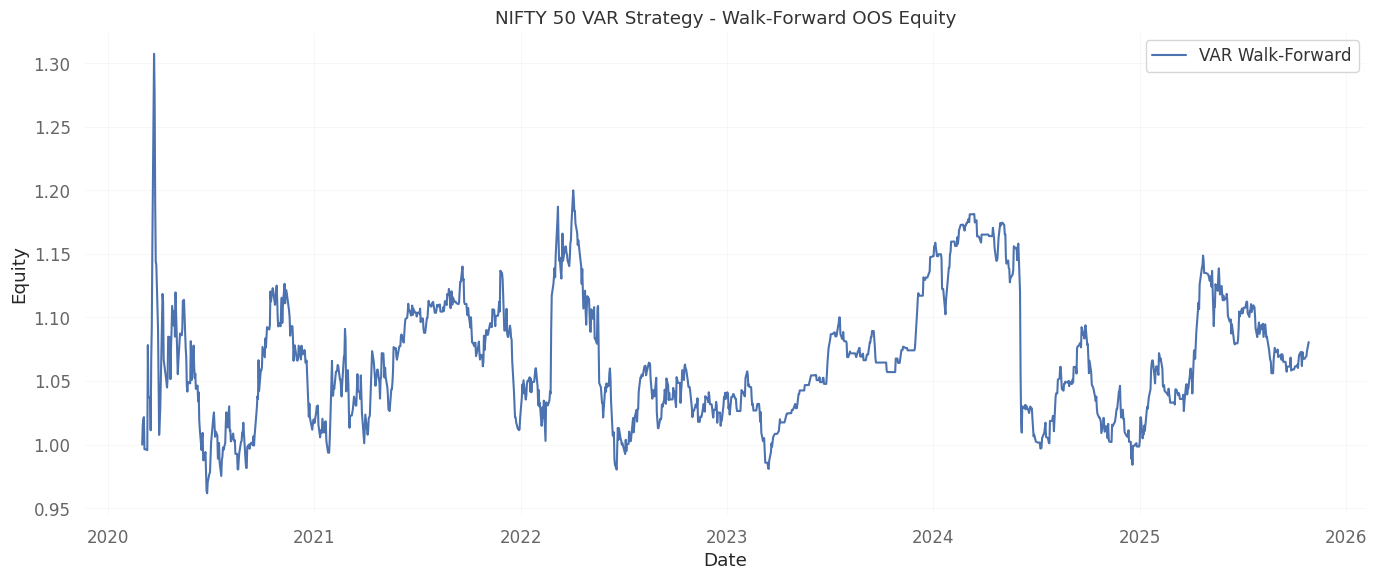

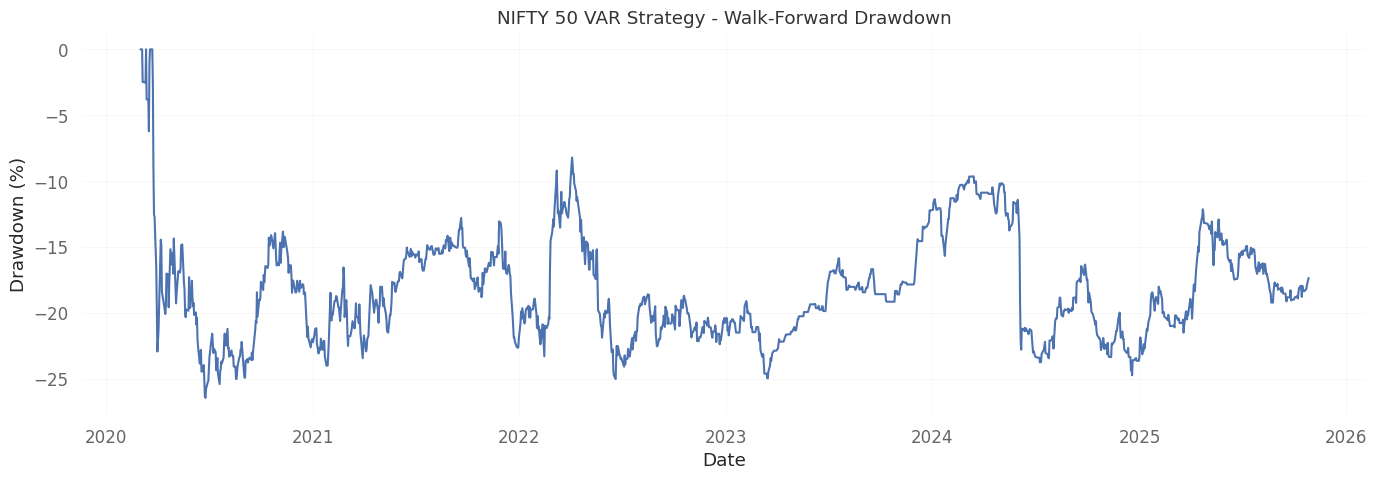



FILES SAVED
NIFTY_VAR_WalkForward_Equity.png
NIFTY_VAR_WalkForward_Drawdown.png
NIFTY_VAR_WalkForward_QuantStats.html
NIFTY_VAR_WalkForward_Results.csv


In [ ]:
# ============================================================
# VAR TRADING STRATEGY
# WALK-FORWARD OUT-OF-SAMPLE TEST
# NIFTY 50
# ============================================================

!pip install yfinance statsmodels quantstats -q

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
import quantstats as qs


# ============================================================
# 1. DOWNLOAD NIFTY 50 DATA
# ============================================================

ticker = "^NSEI"

data = yf.download(
    ticker,
    start="2018-01-01",
    end="2026-01-01",
    auto_adjust=False,
    progress=False
)

if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data[["Open", "High", "Low", "Close", "Volume"]].dropna()

print("=" * 70)
print("NIFTY 50 DATA")
print("=" * 70)
print("Data shape:", data.shape)
print(data.head())


# ============================================================
# 2. CREATE VAR VARIABLES
# ============================================================

df = data.copy()

df["Return"] = df["Close"].pct_change()

# Realized volatility
df["Volatility"] = (
    df["Return"]
    .rolling(10)
    .std()
)

# Volume percentage change
df["Volume_Change"] = (
    df["Volume"]
    .pct_change()
)

# Intraday range
df["Range"] = (
    (df["High"] - df["Low"]) / df["Close"]
)

var_df = df[
    ["Return", "Volatility", "Volume_Change", "Range"]
].dropna()

var_df = var_df.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

print("\nVAR dataset shape:", var_df.shape)


# ============================================================
# 3. PARAMETERS
# ============================================================

TRAIN_SIZE = 504       # approximately 2 trading years
TEST_SIZE = 126        # approximately 6 months

MAX_LAGS = 10

# Trading threshold
THRESHOLD = 0.0005


# ============================================================
# 4. WALK-FORWARD FUNCTION
# ============================================================

def walk_forward_var(
    data,
    train_size=504,
    test_size=126,
    max_lags=10,
    threshold=0.0005
):

    results = []
    all_returns = []

    window = 0
    start = 0

    while True:

        train_start = start
        train_end = start + train_size

        test_start = train_end
        test_end = test_start + test_size

        if test_end > len(data):
            break

        train = data.iloc[
            train_start:train_end
        ].copy()

        test = data.iloc[
            test_start:test_end
        ].copy()

        window += 1

        print("\n" + "=" * 70)
        print(f"WALK-FORWARD WINDOW {window}")
        print("=" * 70)

        print(
            "Training:",
            train.index[0].date(),
            "→",
            train.index[-1].date()
        )

        print(
            "Testing:",
            test.index[0].date(),
            "→",
            test.index[-1].date()
        )

        # ----------------------------------------------------
        # Fit VAR only on training data
        # ----------------------------------------------------

        model = VAR(train)

        # Select lag using AIC
        lag_selection = model.select_order(
            maxlags=max_lags
        )

        selected_lag = lag_selection.aic

        # Safety check
        if selected_lag is None:
            selected_lag = 5

        selected_lag = int(selected_lag)

        # Prevent excessive lag
        selected_lag = min(
            selected_lag,
            max_lags
        )

        if selected_lag < 1:
            selected_lag = 1

        print(
            "Selected VAR lag:",
            selected_lag
        )

        fitted_model = model.fit(
            selected_lag
        )

        # ----------------------------------------------------
        # Generate OOS forecasts
        # ----------------------------------------------------

        predictions = []

        # Initial history
        history = train.copy()

        for date in test.index:

            try:

                forecast_input = history.values[
                    -selected_lag:
                ]

                forecast = fitted_model.forecast(
                    y=forecast_input,
                    steps=1
                )

                predicted_return = forecast[0][0]

            except Exception:

                predicted_return = 0.0

            predictions.append(
                predicted_return
            )

            # Add actual observation AFTER prediction
            # This prevents look-ahead bias
            history = pd.concat(
                [history, test.loc[[date]]]
            )

            # Refit model using information available
            # up to the current date
            model = VAR(history)

            try:

                fitted_model = model.fit(
                    selected_lag
                )

            except Exception:

                fitted_model = VAR(history).fit(
                    1
                )

        test = test.copy()

        test["Forecast"] = predictions

        # ----------------------------------------------------
        # Trading signal
        # ----------------------------------------------------

        test["Signal"] = 0

        test.loc[
            test["Forecast"] > threshold,
            "Signal"
        ] = 1

        test.loc[
            test["Forecast"] < -threshold,
            "Signal"
        ] = -1

        # ----------------------------------------------------
        # Strategy return
        #
        # Signal generated using today's information
        # is applied to NEXT day's return.
        # ----------------------------------------------------

        test["Strategy_Return"] = (
            test["Signal"].shift(1)
            * test["Return"]
        )

        test["Strategy_Return"] = (
            test["Strategy_Return"]
            .fillna(0)
        )

        all_returns.append(
            test["Strategy_Return"]
        )

        # ----------------------------------------------------
        # Window statistics
        # ----------------------------------------------------

        cumulative_return = (
            (1 + test["Strategy_Return"])
            .prod() - 1
        )

        annualized_return = (
            (1 + cumulative_return)
            ** (252 / len(test))
            - 1
        )

        volatility = (
            test["Strategy_Return"]
            .std() * np.sqrt(252)
        )

        if volatility > 0:

            sharpe = (
                test["Strategy_Return"].mean()
                / test["Strategy_Return"].std()
                * np.sqrt(252)
            )

        else:

            sharpe = np.nan

        equity = (
            1 +
            test["Strategy_Return"]
        ).cumprod()

        drawdown = (
            equity /
            equity.cummax()
            - 1
        )

        max_drawdown = drawdown.min()

        trades = (
            test["Signal"]
            .diff()
            .abs()
            .gt(0)
            .sum()
        )

        print(
            f"OOS Return: {cumulative_return * 100:.2f}%"
        )

        print(
            f"OOS CAGR: {annualized_return * 100:.2f}%"
        )

        print(
            f"OOS Sharpe: {sharpe:.2f}"
        )

        print(
            f"OOS Max Drawdown: "
            f"{max_drawdown * 100:.2f}%"
        )

        print(
            f"Trades: {trades}"
        )

        results.append({

            "Window": window,

            "Train Start":
                train.index[0],

            "Train End":
                train.index[-1],

            "Test Start":
                test.index[0],

            "Test End":
                test.index[-1],

            "VAR Lag":
                selected_lag,

            "Return":
                cumulative_return * 100,

            "CAGR":
                annualized_return * 100,

            "Sharpe":
                sharpe,

            "Max Drawdown":
                max_drawdown * 100,

            "Trades":
                trades

        })

        # Move forward by test period
        start += test_size

    # Combine all OOS returns

    all_returns = pd.concat(
        all_returns
    )

    return (
        pd.DataFrame(results),
        all_returns
    )


# ============================================================
# 5. RUN WALK-FORWARD TEST
# ============================================================

wf_results, wf_returns = walk_forward_var(
    var_df,
    train_size=TRAIN_SIZE,
    test_size=TEST_SIZE,
    max_lags=MAX_LAGS,
    threshold=THRESHOLD
)


# ============================================================
# 6. WALK-FORWARD RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("WALK-FORWARD RESULTS")
print("=" * 70)

print(
    wf_results.to_string(
        index=False
    )
)


# ============================================================
# 7. WALK-FORWARD SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("WALK-FORWARD SUMMARY")
print("=" * 70)

print(
    f"Number of OOS windows: "
    f"{len(wf_results)}"
)

print(
    f"Average OOS Return: "
    f"{wf_results['Return'].mean():.2f}%"
)

print(
    f"Median OOS Return: "
    f"{wf_results['Return'].median():.2f}%"
)

print(
    f"Average OOS CAGR: "
    f"{wf_results['CAGR'].mean():.2f}%"
)

print(
    f"Average OOS Sharpe: "
    f"{wf_results['Sharpe'].mean():.2f}"
)

print(
    f"Median OOS Sharpe: "
    f"{wf_results['Sharpe'].median():.2f}"
)

print(
    f"Positive OOS Windows: "
    f"{(wf_results['Return'] > 0).sum()} / "
    f"{len(wf_results)}"
)

print(
    f"Positive OOS Sharpe Windows: "
    f"{(wf_results['Sharpe'] > 0).sum()} / "
    f"{len(wf_results)}"
)


# ============================================================
# 8. COMBINED OOS PERFORMANCE
# ============================================================

print("\n")
print("=" * 70)
print("COMBINED OUT-OF-SAMPLE PERFORMANCE")
print("=" * 70)

oos_equity = (
    1 + wf_returns
).cumprod()

oos_return = (
    oos_equity.iloc[-1] - 1
)

oos_cagr = (
    oos_equity.iloc[-1]
    ** (252 / len(wf_returns))
    - 1
)

oos_volatility = (
    wf_returns.std()
    * np.sqrt(252)
)

oos_sharpe = (
    wf_returns.mean()
    / wf_returns.std()
    * np.sqrt(252)
)

oos_drawdown = (
    oos_equity /
    oos_equity.cummax()
    - 1
)

oos_max_dd = oos_drawdown.min()

print(
    f"OOS Return: "
    f"{oos_return * 100:.2f}%"
)

print(
    f"OOS CAGR: "
    f"{oos_cagr * 100:.2f}%"
)

print(
    f"OOS Volatility: "
    f"{oos_volatility * 100:.2f}%"
)

print(
    f"OOS Sharpe: "
    f"{oos_sharpe:.2f}"
)

print(
    f"OOS Max Drawdown: "
    f"{oos_max_dd * 100:.2f}%"
)


# ============================================================
# 9. EQUITY CURVE
# ============================================================

plt.figure(
    figsize=(14, 6)
)

plt.plot(
    oos_equity,
    label="VAR Walk-Forward"
)

plt.title(
    "NIFTY 50 VAR Strategy - Walk-Forward OOS Equity"
)

plt.xlabel("Date")
plt.ylabel("Equity")

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "NIFTY_VAR_WalkForward_Equity.png",
    dpi=300
)

plt.show()


# ============================================================
# 10. DRAWDOWN
# ============================================================

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    oos_drawdown * 100
)

plt.title(
    "NIFTY 50 VAR Strategy - Walk-Forward Drawdown"
)

plt.xlabel("Date")
plt.ylabel("Drawdown (%)")

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "NIFTY_VAR_WalkForward_Drawdown.png",
    dpi=300
)

plt.show()


# ============================================================
# 11. QUANTSTATS
# ============================================================

wf_returns.index = pd.DatetimeIndex(
    wf_returns.index
)

wf_returns.name = "VAR_WalkForward"

qs.reports.html(
    wf_returns,
    output="NIFTY_VAR_WalkForward_QuantStats.html",
    title="NIFTY 50 VAR Walk-Forward Strategy"
)

print("\n")
print("=" * 70)
print("FILES SAVED")
print("=" * 70)

print(
    "NIFTY_VAR_WalkForward_Equity.png"
)

print(
    "NIFTY_VAR_WalkForward_Drawdown.png"
)

print(
    "NIFTY_VAR_WalkForward_QuantStats.html"
)

print(
    "NIFTY_VAR_WalkForward_Results.csv"
)


# Save results
wf_results.to_csv(
    "NIFTY_VAR_WalkForward_Results.csv",
    index=False
)